In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("std_dataset.csv")

In [4]:
df.head()

,Student ID,Session ID,Date,EEG Data (PSD Features),Engagement Level,Attention Level,Internet Connectivity,Adaptivity Level,Learning Mode Prediction,Performance Metrics
0,1,183,2025-01-20,"[0.02336871035675725, 0.14892576656473, 0.4845...",High,High,High (Mobile/Wi-Fi),Moderate,Visual Learner,84
1,2,121,2025-01-20,"[0.3587673311624021, 0.8537981137219391, 0.420...",Low,High,Moderate (Wi-Fi),High,Auditory Learner,82
2,3,169,2025-01-10,"[0.7420744093003028, 0.9072353407615483, 0.122...",Moderate,High,Low (Mobile),Low,Auditory Learner,83
3,4,132,2025-01-20,"[0.5596059164442914, 0.4645215049524961, 0.062...",High,Moderate,Low (Mobile),Moderate,Visual Learner,66
4,5,190,2025-01-18,"[0.15041646487754368, 0.7331633184349893, 0.86...",High,High,High (Mobile/Wi-Fi),Moderate,Auditory Learner,93


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Student ID                10000 non-null  int64
 1   Session ID                10000 non-null  int64
 2   Date                      10000 non-null  str  
 3   EEG Data (PSD Features)   10000 non-null  str  
 4   Engagement Level          10000 non-null  str  
 5   Attention Level           10000 non-null  str  
 6   Internet Connectivity     10000 non-null  str  
 7   Adaptivity Level          10000 non-null  str  
 8   Learning Mode Prediction  10000 non-null  str  
 9   Performance Metrics       10000 non-null  int64
dtypes: int64(3), str(7)
memory usage: 1.9 MB


In [6]:
df.describe()

,Student ID,Session ID,Performance Metrics
count,10000.00000,10000.000000,10000.000000
mean,5000.50000,149.762700,74.674300
std,2886.89568,28.783232,14.383404
min,1.00000,100.000000,50.000000
25%,2500.75000,125.000000,62.000000
50%,5000.50000,150.000000,75.000000
75%,7500.25000,174.000000,87.000000
max,10000.00000,199.000000,99.000000


In [7]:
df.isnull().sum()

Student ID                  0
Session ID                  0
Date                        0
EEG Data (PSD Features)     0
Engagement Level            0
Attention Level             0
Internet Connectivity       0
Adaptivity Level            0
Learning Mode Prediction    0
Performance Metrics         0
dtype: int64

In [8]:
df['Performance Metrics'].value_counts()
df['Student ID'].value_counts()
df['Session ID'].value_counts()

Session ID
164    133
162    127
140    125
138    120
110    119
      ... 
158     85
116     85
125     84
133     83
181     82
Name: count, Length: 100, dtype: int64

In [9]:
daily_avg = df.groupby('Date')[['Engagement Level','Attention Level']].agg(lambda x: x.mode()[0])

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29],
 [Text(0, 0, '2025-01-01'),
  Text(1, 0, '2025-01-02'),
  Text(2, 0, '2025-01-03'),
  Text(3, 0, '2025-01-04'),
  Text(4, 0, '2025-01-05'),
  Text(5, 0, '2025-01-06'),
  Text(6, 0, '2025-01-07'),
  Text(7, 0, '2025-01-08'),
  Text(8, 0, '2025-01-09'),
  Text(9, 0, '2025-01-10'),
  Text(10, 0, '2025-01-11'),
  Text(11, 0, '2025-01-12'),
  Text(12, 0, '2025-01-13'),
  Text(13, 0, '2025-01-14'),
  Text(14, 0, '2025-01-15'),
  Text(15, 0, '2025-01-16'),
  Text(16, 0, '2025-01-17'),
  Text(17, 0, '2025-01-18'),
  Text(18, 0, '2025-01-19'),
  Text(19, 0, '2025-01-20'),
  Text(20, 0, '2025-01-21'),
  Text(21, 0, '2025-01-22'),
  Text(22, 0, '2025-01-23'),
  Text(23, 0, '2025-01-24'),
  Text(24, 0, '2025-01-25'),
  Text(25, 0, '2025-01-26'),
  Text(26, 0, '2025-01-27'),
  Text(27, 0, '2025-01-28'),
  Text(28, 0, '2025-01-29')

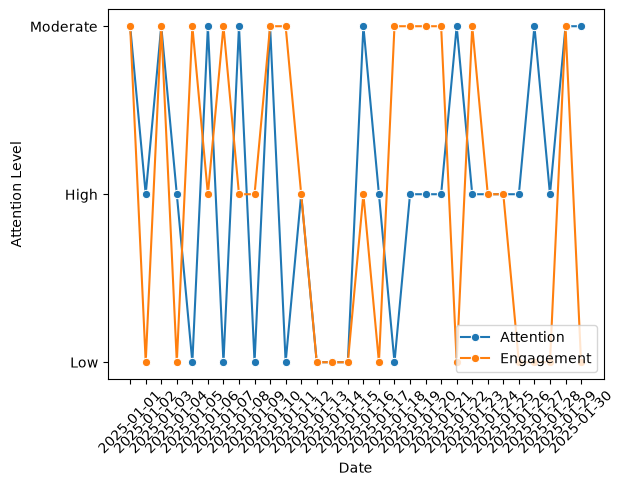

In [10]:
sns.lineplot(data=daily_avg, x='Date', y='Attention Level',marker='o', label='Attention')
sns.lineplot(data=daily_avg, x='Date', y='Engagement Level',marker='o', label='Engagement')

plt.xticks(rotation=45)


In [13]:
df['Engagement Level'] = df['Engagement Level'].map({'Low': 1,'Moderate': 2,'High': 3})
df['Attention Level'] = df['Attention Level'].map({'Low': 1,'Moderate': 2,'High': 3})

In [15]:
performance = df.groupby('Student ID')[['Attention Level', 'Engagement Level']].mean().reset_index()

In [16]:
performance = performance.sort_values('Engagement Level')

top_10 = performance.tail(10)
bottom_10 = performance.head(10)

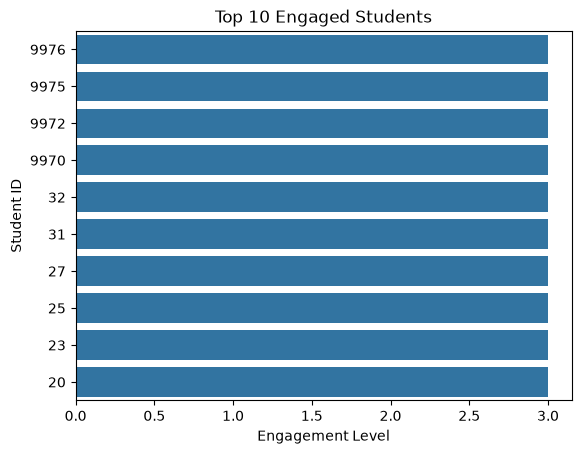

In [20]:
top_10['Student ID'] = top_10['Student ID'].astype(str)
sns.barplot(data=top_10, x='Engagement Level', y='Student ID')
plt.title('Top 10 Engaged Students')
plt.show()

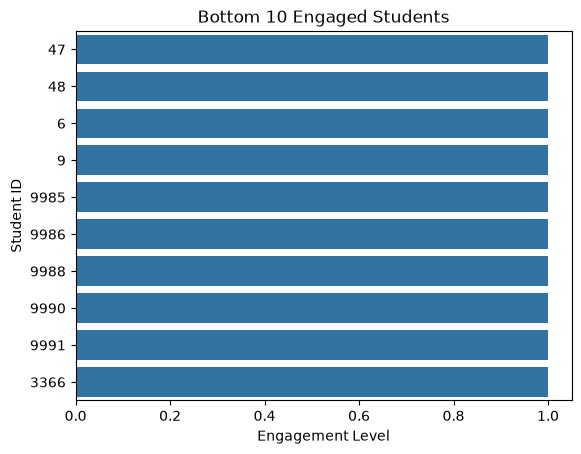

In [19]:
bottom_10['Student ID'] = bottom_10['Student ID'].astype(str)
sns.barplot(data=bottom_10, x='Engagement Level', y='Student ID')
plt.title('Bottom 10 Engaged Students')
plt.show()

In [26]:
modes = df.groupby('Learning Mode Prediction')['Engagement Level'].mean().reset_index()


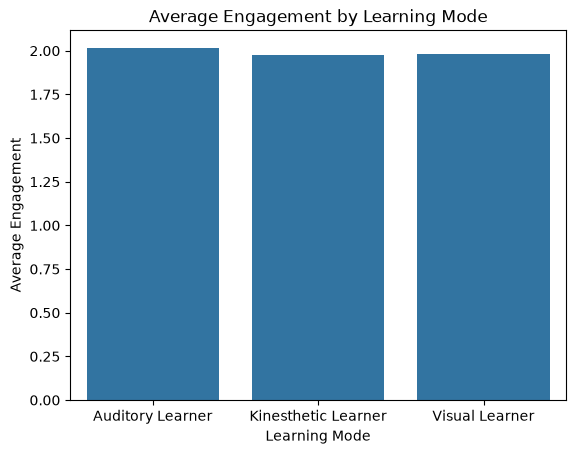

In [27]:
sns.barplot(data=modes, x='Learning Mode Prediction', y='Engagement Level')
plt.title('Average Engagement by Learning Mode')
plt.xlabel('Learning Mode')
plt.ylabel('Average Engagement')
plt.show()